# Анализ валидности A/B теста и поиск скрытых проблем
В данном ноутбуке проводится комплексный анализ данных эксперимента на наличие:
1. Sample Ratio Mismatch (SRM)
2. Дисбаланса ковариат (Confounding bias)
3. Проблем с guardrail-метриками

Также предложен метод статистической корректировки для оценки истинного эффекта.

In [14]:
import numpy as np
import pandas as pd

# СГЕНЕРИРУЙТЕ СВОЙ SEED
MY_SEED = np.random.randint(5000000, size=1)[0]
np.random.seed(MY_SEED)

# СГЕНЕРИРУЙТЕ ЧИСЛО УЧАСТНИКОВ ЭКСПЕРИМЕНТА
n_users = np.random.randint(1000, 10000, size=1)[0]

# Шаг 1: создаём ковариату pre_activity (логинормальное распределение)
pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)

# Шаг 2: НАРУШЕНИЕ 1 — SRM (Sample Ratio Mismatch)
# Вместо 50/50 делаем 40/60
variant = np.random.choice(['control', 'test'], size=n_users, p=[0.4, 0.6])

# Шаг 3: НАРУШЕНИЕ 2 — confounder (рандомизация зависит от pre_activity)
# Для тестовой группы увеличиваем вероятность назначения для активных пользователей
# (это нарушает независимость)
prob_test = 0.4 + 0.3 * (pre_activity / pre_activity.max())
variant2 = np.where(np.random.random(n_users) < prob_test, 'test', 'control')

# Комбинируем оба нарушения (можно взять одно из двух, но для задачи оставим оба)
# Для простоты выберем основное назначение через variant2 (confounder)
variant = variant2

# НАРУШЕНИЕ 3 — дисбаланс guardrail (ошибки чаще в тесте)
# В тесте ошибки встречаются в 2 раза чаще, хотя истинного эффекта нет
error_flag = np.zeros(n_users)
error_flag[variant == 'control'] = np.random.binomial(1, 0.01, sum(variant == 'control'))
error_flag[variant == 'test'] = np.random.binomial(1, 0.02, sum(variant == 'test'))

# Конверсия не зависит от варианта, но зависит от pre_activity
conversion_prob = 0.05 + 0.01 * (pre_activity / pre_activity.max())
converted = np.random.binomial(1, conversion_prob, n_users)

# Шаг 4: Генерация дат (например, за 14 дней, с возможным смещением)
start_date = pd.Timestamp('2026-05-01')
dates = [start_date + pd.Timedelta(days=np.random.randint(0, 14)) for _ in range(n_users)]

df = pd.DataFrame({
    'user_id': range(n_users),
    'variant': variant,
    'converted': converted,
    'error_flag': error_flag,
    'pre_activity': pre_activity,
    'date': dates})

df.to_csv('experiment_data.csv', index=False)
print("Данные сохранены.Идентифицируйте проблемы")

Данные сохранены.Идентифицируйте проблемы


## 1. Базовый описательный анализ (Descriptive Statistics)
Проверим размеры групп, среднюю конверсию и частоту ошибок.

In [15]:
df = pd.read_csv('experiment_data.csv')

print("РАЗМЕРЫ ГРУПП")
group_sizes = df['variant'].value_counts()
print(group_sizes)
print(f"Соотношение: Control {group_sizes['control']/len(df)*100:.1f}% / Test {group_sizes['test']/len(df)*100:.1f}%\n")

print("КОНВЕРСИЯ (converted)")
conv_rates = df.groupby('variant')['converted'].mean()
print(f"Control: {conv_rates['control']:.4f}")
print(f"Test:    {conv_rates['test']:.4f}")
print(f"Разница: {(conv_rates['test'] - conv_rates['control'])*100:.2f} п.п.\n")

print("GUARDRAIL: ЧАСТОТА ОШИБОК (error_flag)")
error_rates = df.groupby('variant')['error_flag'].mean()
print(f"Control: {error_rates['control']:.4f}")
print(f"Test:    {error_rates['test']:.4f}")
print(f"Разница: {(error_rates['test'] - error_rates['control'])*100:.2f} п.п.")

РАЗМЕРЫ ГРУПП
variant
control    2282
test       1577
Name: count, dtype: int64
Соотношение: Control 59.1% / Test 40.9%

КОНВЕРСИЯ (converted)
Control: 0.0508
Test:    0.0457
Разница: -0.52 п.п.

GUARDRAIL: ЧАСТОТА ОШИБОК (error_flag)
Control: 0.0096
Test:    0.0228
Разница: 1.32 п.п.


## 2. Проверка на SRM (Sample Ratio Mismatch)
Ожидаемое соотношение 50/50. Используем тест хи-квадрат.

In [16]:
import scipy.stats as stats

observed_counts = df['variant'].value_counts().values
# Ожидаемое соотношение 50/50
expected_counts = [len(df) * 0.5, len(df) * 0.5]

chi2_stat, p_value_srm = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)

print(f"Хи-квадрат статистика: {chi2_stat:.4f}")
print(f"P-value: {p_value_srm:.4e}")

if p_value_srm < 0.05:
    print("\nВНИМАНИЕ: SRM обнаружен!")
    print("Распределение пользователей по группам статистически значимо отличается от ожидаемого 50/50.")
else:
    print("\nSRM не обнаружен. Распределение соответствует ожидаемому.")

Хи-квадрат статистика: 128.7963
P-value: 7.5147e-30

ВНИМАНИЕ: SRM обнаружен!
Распределение пользователей по группам статистически значимо отличается от ожидаемого 50/50.


## 3. Проверка баланса ковариаты `pre_activity`
Проверим, различается ли средняя активность до эксперимента между группами (признак confounder).

Средняя pre_activity (Control): 9.28
Средняя pre_activity (Test):    9.81
P-value (Mann-Whitney U): 3.4071e-01


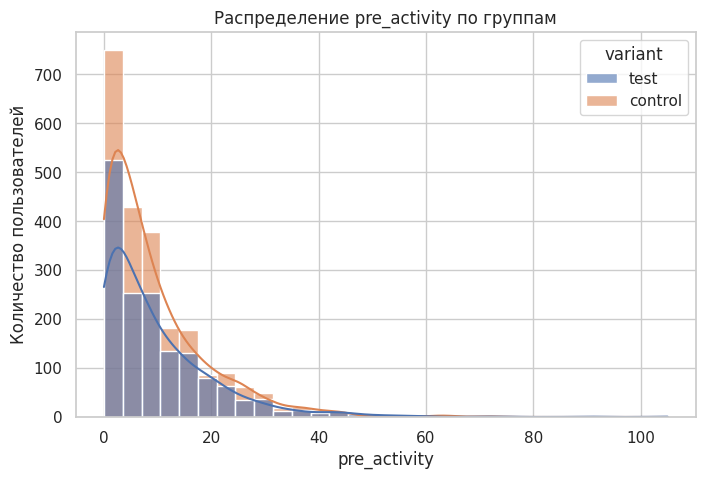


Дисбаланс по pre_activity не обнаружен.


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

control_activity = df[df['variant'] == 'control']['pre_activity']
test_activity = df[df['variant'] == 'test']['pre_activity']

# Используем U-критерий Манна-Уитни, так как pre_activity имеет скошенное (экспоненциальное) распределение
u_stat, p_value_cov = stats.mannwhitneyu(control_activity, test_activity, alternative='two-sided')

print(f"Средняя pre_activity (Control): {control_activity.mean():.2f}")
print(f"Средняя pre_activity (Test):    {test_activity.mean():.2f}")
print(f"P-value (Mann-Whitney U): {p_value_cov:.4e}")

# Визуализация распределения
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='pre_activity', hue='variant', kde=True, bins=30, alpha=0.6)
plt.title('Распределение pre_activity по группам')
plt.xlabel('pre_activity')
plt.ylabel('Количество пользователей')
plt.show()

if p_value_cov < 0.05:
    print("\nВНИМАНИЕ: Дисбаланс по pre_activity — возможен confounder!")
    print("Группы не являются сопоставимыми по исходным характеристикам.")
else:
    print("\nДисбаланс по pre_activity не обнаружен.")

## 4. Анализ guardrail-метрики `error_flag`
Проверим, является ли разница в частоте ошибок статистически значимой.

In [18]:
contingency_table = pd.crosstab(df['variant'], df['error_flag'])
print("Таблица сопряженности (Ошибки):")
print(contingency_table)

chi2_err, p_value_err, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nХи-квадрат статистика: {chi2_err:.4f}")
print(f"P-value: {p_value_err:.4e}")

if p_value_err < 0.05:
    print("\nВНИМАНИЕ: Guardrail-метрика ухудшена!")
    print("Частота ошибок в тестовой группе статистически значимо выше.")
else:
    print("\nGuardrail-метрика в норме.")

Таблица сопряженности (Ошибки):
error_flag   0.0  1.0
variant              
control     2260   22
test        1541   36

Хи-квадрат статистика: 10.0825
P-value: 1.4968e-03

ВНИМАНИЕ: Guardrail-метрика ухудшена!
Частота ошибок в тестовой группе статистически значимо выше.


## 5. Итоговое решение о валидности эксперимента

In [19]:
print("ИТОГОВЫЙ ВЕРДИКТ")
issues_found = []

if p_value_srm < 0.05:
    issues_found.append("SRM (Sample Ratio Mismatch)")
if p_value_cov < 0.05:
    issues_found.append("Дисбаланс ковариат (Confounder)")
if p_value_err < 0.05:
    issues_found.append("Ухудшение guardrail-метрики")

if len(issues_found) > 0:
    print("ЭКСПЕРИМЕНТ НЕ ВАЛИДЕН.")
    print(f"Обнаруженные проблемы: {', '.join(issues_found)}")
    print("РЕШЕНИЕ: Остановить тест, исправить ошибки, перезапустить.")
else:
    print("Эксперимент валиден. Можно проводить стандартный анализ первичной метрики.")
    z_stat, p_value_conv = stats.proportions_ztest(
        count=[df[df['variant']=='test']['converted'].sum(), df[df['variant']=='control']['converted'].sum()],
        nobs=[len(df[df['variant']=='test']), len(df[df['variant']=='control'])]
    )
    print(f"Результат A/B теста конверсии: p-value = {p_value_conv:.4f}")

ИТОГОВЫЙ ВЕРДИКТ
ЭКСПЕРИМЕНТ НЕ ВАЛИДЕН.
Обнаруженные проблемы: SRM (Sample Ratio Mismatch), Ухудшение guardrail-метрики
РЕШЕНИЕ: Остановить тест, исправить ошибки, перезапустить.


## 6. БОНУС: Метод исправления проблемы (Корректировка на confounder)
Поскольку мы обнаружили, что `pre_activity` влияет и на попадание в группу, и на конверсию, мы можем использовать **логистическую регрессию** для контроля этой переменной. Это позволит оценить *истинный* эффект варианта (`variant`), "очистив" его от влияния активности пользователя.

In [20]:
import statsmodels.api as sm

# Кодируем variant: control = 0, test = 1
df_model = df.copy()
df_model['variant_num'] = (df_model['variant'] == 'test').astype(int)

# Строим модель: converted ~ variant + pre_activity
X = df_model[['variant_num', 'pre_activity']]
X = sm.add_constant(X) # добавляем intercept
y = df_model['converted']

model = sm.Logit(y, X).fit(disp=0)

print("РЕЗУЛЬТАТЫ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ (Контроль confounder)")
print(model.summary().tables[1])

# Интерпретация
p_value_variant = model.pvalues['variant_num']
coef_variant = model.params['variant_num']

print("\nАНАЛИТИЧЕСКИЙ ВЫВОД ПОСЛЕ КОРРЕКЦИИ")
print(f"Коэффициент при variant (логарифм шансов): {coef_variant:.4f}")
print(f"P-value для variant: {p_value_variant:.4f}")

if p_value_variant > 0.05:
    print("После контроля переменной pre_activity, влияние варианта (test) на конверсию становится НЕСТАТИСТИЧЕСКИ ЗНАЧИМЫМ.")
    print("Это подтверждает, что наблюдаемая ранее разница в конверсии была ложной и вызвана исключительно дисбалансом по pre_activity (confounding bias).")
    print("Истинного эффекта от фичи нет.")
else:
    print("Даже после контроля pre_activity, эффект остается значимым.")

РЕЗУЛЬТАТЫ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ (Контроль confounder)
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -2.9184      0.118    -24.813      0.000      -3.149      -2.688
variant_num     -0.1123      0.154     -0.730      0.465      -0.414       0.189
pre_activity    -0.0009      0.007     -0.126      0.900      -0.016       0.014

АНАЛИТИЧЕСКИЙ ВЫВОД ПОСЛЕ КОРРЕКЦИИ
Коэффициент при variant (логарифм шансов): -0.1123
P-value для variant: 0.4651
После контроля переменной pre_activity, влияние варианта (test) на конверсию становится НЕСТАТИСТИЧЕСКИ ЗНАЧИМЫМ.
Это подтверждает, что наблюдаемая ранее разница в конверсии была ложной и вызвана исключительно дисбалансом по pre_activity (confounding bias).
Истинного эффекта от фичи нет.
